# AISE 4010 Course Project — Group 1

**Stage 1 (Lab 6): Data, Traditional Baselines, MLP and CNN**

Lab section 3 · Dataset 4 in the verified pool (Open Power System Data)

Day-ahead forecasting of Germany's hourly electricity load with the Open Power System Data (OPSD) time series package.

| Stage 1 requirement | Section |
|---|---|
| Source, target, unit, frequency, resampling, coverage, gaps, duplicates, missingness | 1, 2 |
| Exploratory figures | 3, 4 |
| Chronological split, imputer, scaler, window shapes | 3, 5 |
| Traditional baselines | 6 |
| MLP and CNN under the same protocol | 7, 8, 9 |
| Grid search for the best model | 10 |
| Test comparison: metrics, parameters, training time, baseline improvement | 11 |
| Saved model and smoke test | 12 |
| Conclusion and unresolved risk | 13 |

Run the cells top to bottom in a fresh kernel (about 5–10 minutes on a laptop CPU). A GPU is not needed; the notebook also runs unchanged on Google Colab.

## Settings

Run first. The determinism flags and fixed seed follow the lab notebooks so every number below can be reproduced.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"  # CPU only: the models are small and one device keeps timings comparable
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hides a harmless tf.data version notice that TF 2.20 logs on every fit

import json
import logging
import platform
import time
import urllib.request
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Conv1D, Dense, Flatten, MaxPooling1D
from tensorflow.keras.optimizers import Adam

SEED = 4010
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # Arial is missing on Colab; fall back quietly
plt.rcParams.update({
    "font.family": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "figure.dpi": 110,
})
BLACK, GREY, LIGHT, ACCENT = "#000000", "#7a7a7a", "#c4c4c4", "#1f5aa6"

print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "|", platform.platform())
print("Devices:", [d.device_type for d in tf.config.list_physical_devices()], "| seed", SEED)

Python 3.13.13 | TensorFlow 2.20.0 | macOS-27.0.1-arm64-arm-64bit-Mach-O
Devices: ['CPU'] | seed 4010


## 1. Problem Definition

| Item | Choice |
|---|---|
| Dataset | OPSD Time series package, version 2020-10-06, file `time_series_60min_singleindex.csv` |
| Target | `DE_load_actual_entsoe_transparency`: total electricity load of Germany reported to ENTSO-E |
| Unit | MW (hourly average) |
| Native frequency | 1 hour, UTC timestamps |
| Resampling rule | None; the series is already on a complete hourly grid (audit in Section 2) |
| Lookback | 168 h (one week), justified by the autocorrelation in Section 4 |
| Horizon | Next 24 h, predicted in one shot (direct multi-output forecast, one output per hour) |
| Inputs | Past 168 h of load plus hour-of-day and day-of-week encodings (calendar values are known in advance) |
| Split | Chronological 60 / 20 / 20 (train / validation / test), never shuffled across time |
| Metrics | MAE, RMSE and MAPE in original units, plus improvement over the best traditional baseline |
| Selection metric | Validation RMSE (MW); the test set is used once, in Section 11 |

**Operational interpretation.** Every hour the model issues a forecast of national load for the next 24 hours. Grid operators and market participants use forecasts like this to schedule generation and buy balancing reserves, so an error of 1,000 MW is roughly the output of one large power plant that was planned but not needed (or missing).

## 2. Data Loading and Audit

### 2.1 Download

The raw OPSD file (about 124 MB) is downloaded once into `data/` and is not committed to GitHub. Only the timestamp and target columns are read.

In [2]:
DATA_DIR = "data"
DATA_FILE = os.path.join(DATA_DIR, "time_series_60min_singleindex.csv")
DATA_URL = "https://data.open-power-system-data.org/time_series/2020-10-06/time_series_60min_singleindex.csv"
TARGET = "DE_load_actual_entsoe_transparency"

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

raw = pd.read_csv(DATA_FILE, usecols=["utc_timestamp", TARGET],
                  parse_dates=["utc_timestamp"], index_col="utc_timestamp")
series = raw[TARGET].rename("load_MW")
print("Rows read:", len(series), "| columns used:", ["utc_timestamp", TARGET])

Rows read: 50401 | columns used: ['utc_timestamp', 'DE_load_actual_entsoe_transparency']


### 2.2 Timestamp and Missing-Value Audit

The audit checks coverage, duplicated timestamps, steps that break the hourly grid and missing values before anything else touches the data.

**Table 1.** Data audit of the target series.

In [3]:
series = series.loc[series.first_valid_index():series.last_valid_index()]  # trim empty edge rows outside the target's coverage

steps = series.index.to_series().diff().dropna()
missing = series.isna()
longest_gap = int(missing.groupby((~missing).cumsum()).sum().max())

audit = pd.Series({
    "First timestamp (UTC)": series.index.min(),
    "Last timestamp (UTC)": series.index.max(),
    "Rows": len(series),
    "Expected hourly rows": len(pd.date_range(series.index.min(), series.index.max(), freq="h")),
    "Duplicated timestamps": int(series.index.duplicated().sum()),
    "Steps other than 1 h": int((steps.dt.total_seconds() != 3600).sum()),
    "Missing values": int(missing.sum()),
    "Longest missing run (h)": longest_gap,
    "Minimum load (MW)": series.min(),
    "Mean load (MW)": round(series.mean(), 1),
    "Maximum load (MW)": series.max(),
}, name="value")
display(audit.to_frame())

,value
First timestamp (UTC),2015-01-01 00:00:00+00:00
Last timestamp (UTC),2020-09-30 23:00:00+00:00
Rows,50400
Expected hourly rows,50400
Duplicated timestamps,0
Steps other than 1 h,0
Missing values,0
Longest missing run (h),0
Minimum load (MW),31307.0
Mean load (MW),55492.5


The target covers 1 January 2015 to 30 September 2020 on a complete hourly UTC grid with no duplicates, gaps or missing values, so no resampling is needed. Timestamps stay in UTC, which avoids the repeated and skipped hours of daylight-saving time; local time (Europe/Berlin) is used only for the calendar features, because demand follows local clocks. The `DE` column is used rather than `DE_LU` because the Germany–Luxembourg bidding-zone series only starts on 1 October 2018.

**What the target measures.** OPSD takes this column from the ENTSO-E Transparency Platform, where total load is defined as total generation, minus the power plants' own consumption, plus imports, minus exports, minus consumption by storage (for example pumped hydro). It covers load served through the grid; industrial self-generation that never enters the transmission grid is not included, so the annual total is slightly below ENTSO-E's monthly statistics (about 490 versus 500 TWh per year for Germany, according to the OPSD documentation). Germany reports in 15-minute steps; the 60-minute file holds hourly averages.

**Gap filling by OPSD.** "0 missing values" describes the published file, not the raw TSO data. Before publishing, OPSD filled gaps of up to 2 hours by linear interpolation (mostly at daylight-saving changes) and left longer gaps empty, and this file version has no marker column showing which hours were filled. Linear interpolation uses the next observed value, so a filled hour carries a little future information. With gaps of at most 2 hours the effect is negligible, but it is a property of the source data that this pipeline cannot undo.

## 3. Chronological Split and Imputation

### 3.1 Split First

The raw series is split 60 / 20 / 20 in time order **before** any imputation, scaling or windowing (Lab 3 rule), so no statistic from the validation or test period can reach training.

**Table 2.** Chronological split of the hourly series.

In [4]:
n = len(series)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train_raw = series.iloc[:train_end].copy()
val_raw = series.iloc[train_end:val_end].copy()
test_raw = series.iloc[val_end:].copy()

splits = {"train": train_raw, "validation": val_raw, "test": test_raw}
split_table = pd.DataFrame({
    "start (UTC)": [s.index.min() for s in splits.values()],
    "end (UTC)": [s.index.max() for s in splits.values()],
    "hours": [len(s) for s in splits.values()],
    "share (%)": [round(100 * len(s) / n, 1) for s in splits.values()],
}, index=list(splits))
display(split_table)

,start (UTC),end (UTC),hours,share (%)
train,2015-01-01 00:00:00+00:00,2018-06-13 23:00:00+00:00,30240,60.0
validation,2018-06-14 00:00:00+00:00,2019-08-07 23:00:00+00:00,10080,20.0
test,2019-08-08 00:00:00+00:00,2020-09-30 23:00:00+00:00,10080,20.0


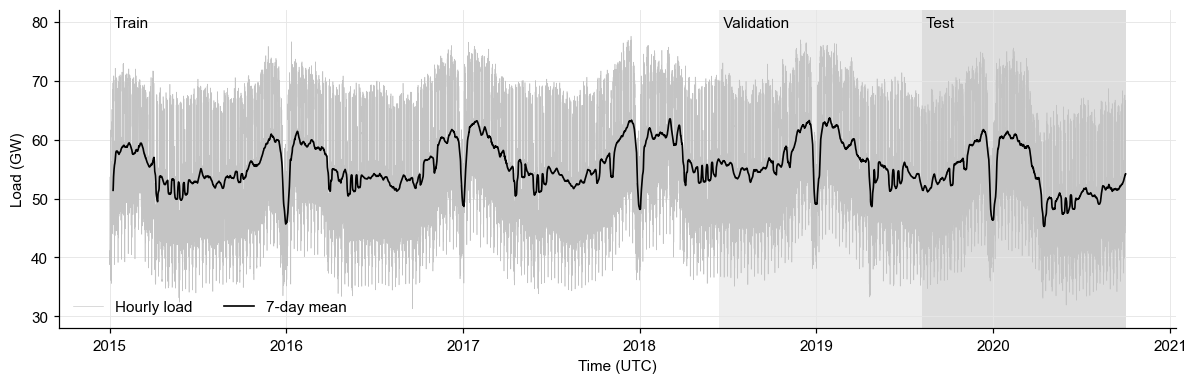

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(series.index, series / 1000, color=LIGHT, linewidth=0.4, label="Hourly load")
ax.plot(series.index, series.rolling(24 * 7).mean() / 1000, color=BLACK, linewidth=1.1, label="7-day mean")
ax.axvspan(val_raw.index[0], val_raw.index[-1], color=GREY, alpha=0.12, linewidth=0)
ax.axvspan(test_raw.index[0], test_raw.index[-1], color=GREY, alpha=0.25, linewidth=0)
for name, part in splits.items():
    ax.text(part.index[0], 81, f" {name.capitalize()}", va="top")
ax.set_ylim(28, 82)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Load (GW)")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout()
plt.show()

**Fig. 1.** Hourly German load, 2015–2020, with its 7-day mean. The light and dark bands mark the validation and test periods.

Load follows a yearly cycle: the 7-day mean sits around 52–54 GW in summer and 60–63 GW in winter, with a sharp dip over Christmas and New Year every year. The test period contains a regime that training never saw: during the spring 2020 COVID-19 restrictions the 7-day mean fell to about 46 GW, a Christmas-like level that lasted for weeks, and it stayed below earlier summers through September 2020.

### 3.2 Imputer

The imputer is a causal forward fill applied separately to each split: validation and test may only inherit the last value of the block before them, which is already known at forecast time (Lab 3). The audit found no missing values, so this step changes nothing here. It is kept as a safeguard, and the assertion stops the run if a future data version has gaps that would need masking before scoring.

In [6]:
train = train_raw.ffill()
val = pd.concat([train.iloc[-1:], val_raw]).ffill().iloc[1:]
test = pd.concat([val.iloc[-1:], test_raw]).ffill().iloc[1:]

imputed = sum(int(s.isna().sum()) for s in splits.values())
print("Values imputed:", imputed)
assert train.notna().all() and val.notna().all() and test.notna().all()
assert imputed == 0, "Imputed targets must be masked out of scoring (Lab 3, B3)."

Values imputed: 0


## 4. Exploratory Analysis on the Training Split

Design decisions (lookback length and baselines) are based on the training split only, so the validation and test periods cannot influence them.

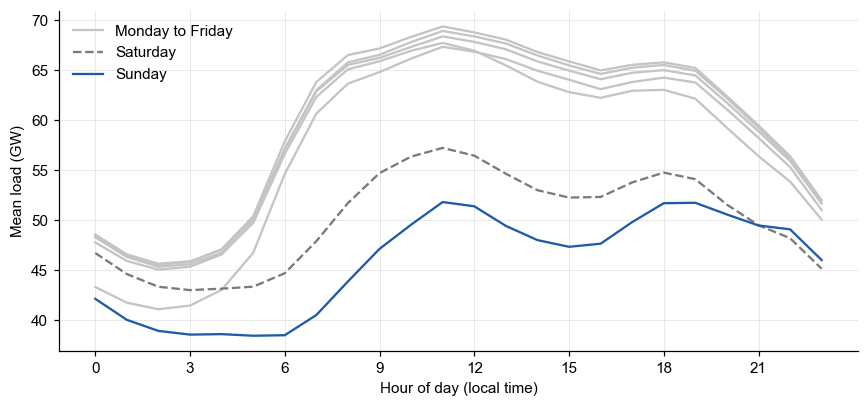

Mean weekday peak (GW): 68.3 | Saturday peak: 57.2 | Sunday peak: 51.8


In [7]:
train_local = train.index.tz_convert("Europe/Berlin")
profile = train.groupby([train_local.dayofweek, train_local.hour]).mean().unstack(0) / 1000  # rows: hour, columns: weekday

fig, ax = plt.subplots(figsize=(8, 3.8))
for day in range(5):
    ax.plot(profile.index, profile[day], color=LIGHT, label="Monday to Friday" if day == 0 else None)
ax.plot(profile.index, profile[5], color=GREY, linestyle="--", label="Saturday")
ax.plot(profile.index, profile[6], color=ACCENT, label="Sunday")
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day (local time)")
ax.set_ylabel("Mean load (GW)")
ax.legend()
plt.tight_layout()
plt.show()

print("Mean weekday peak (GW):", round(profile[[0, 1, 2, 3, 4]].max().mean(), 1),
      "| Saturday peak:", round(profile[5].max(), 1), "| Sunday peak:", round(profile[6].max(), 1))

**Fig. 2.** Mean training-period load by local hour for each day of the week.

All five weekdays share one shape: a steep ramp from 06:00, a late-morning peak (68.3 GW on average) and a second shoulder around 18:00. Saturday peaks at 57.2 GW and Sunday at 51.8 GW, 11–17 GW below a weekday. The day of the week changes the whole daily profile, which is why the weekday encoding is an input and the 168 h seasonal naive is a baseline.

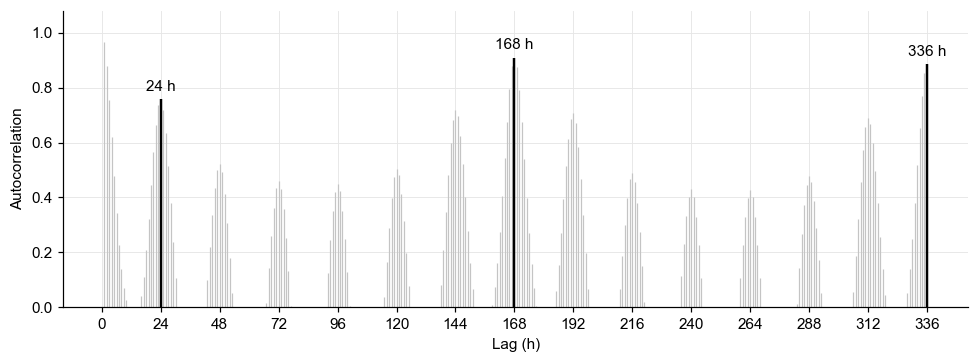

ACF at 24 h: 0.758 | 72 h: 0.46 | 168 h: 0.91 | 336 h: 0.885


In [8]:
lags = np.arange(1, 24 * 14 + 1)
acf = np.array([train.autocorr(lag) for lag in lags])

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.vlines(lags, 0, acf, color=LIGHT, linewidth=0.8)
for lag in (24, 168, 336):
    ax.vlines(lag, 0, acf[lag - 1], color=BLACK, linewidth=1.6)
    ax.text(lag, acf[lag - 1] + 0.03, f"{lag} h", ha="center")
ax.set_xticks(range(0, 24 * 14 + 1, 24))
ax.set_ylim(0, 1.08)
ax.set_xlabel("Lag (h)")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

print("ACF at 24 h:", round(acf[23], 3), "| 72 h:", round(acf[71], 3),
      "| 168 h:", round(acf[167], 3), "| 336 h:", round(acf[335], 3))

**Fig. 3.** Autocorrelation of hourly training load for lags up to two weeks; the 24 h, 168 h and 336 h lags are highlighted.

The autocorrelation peaks every 24 h, and the weekly peaks are the strongest: 0.91 at 168 h and 0.885 at 336 h, against 0.758 at 24 h, because the same hour one week earlier falls on the same type of day while yesterday may be a weekend. A 168 h lookback therefore contains both the previous day and the same hour last week; a two-week lookback adds little, since the 336 h peak is lower than the 168 h one.

## 5. Scaling, Calendar Features and Windows

### 5.1 Scaler

A `StandardScaler` is fitted on the training load only and reused for validation and test (Lab 3, B2).

In [9]:
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1)).ravel()
val_scaled = scaler.transform(val.to_numpy().reshape(-1, 1)).ravel()
test_scaled = scaler.transform(test.to_numpy().reshape(-1, 1)).ravel()

print("Training scaler mean (MW):", round(scaler.mean_[0], 1), "| scale (MW):", round(scaler.scale_[0], 1))

Training scaler mean (MW): 55740.7 | scale (MW): 10063.4


### 5.2 Calendar Features

Hour of day and day of week are known for any future hour, so the project protocol allows them as inputs. Each is encoded as a sine/cosine pair so that 23:00 sits next to 00:00 and Sunday next to Monday. They need no fitting, so they cannot leak information between splits.

In [10]:
FEATURES = ["load (scaled)", "hour sin", "hour cos", "weekday sin", "weekday cos"]

def feature_matrix(scaled_load, index):
    local = index.tz_convert("Europe/Berlin")
    hour = 2 * np.pi * local.hour / 24
    day = 2 * np.pi * local.dayofweek / 7
    return np.column_stack([scaled_load, np.sin(hour), np.cos(hour), np.sin(day), np.cos(day)]).astype("float32")

train_feat = feature_matrix(train_scaled, train.index)
val_feat = feature_matrix(val_scaled, val.index)
test_feat = feature_matrix(test_scaled, test.index)
print("Training feature matrix:", train_feat.shape, FEATURES)

Training feature matrix: (30240, 5) ['load (scaled)', 'hour sin', 'hour cos', 'weekday sin', 'weekday cos']


### 5.3 Sliding Windows

`make_windows` extends the Lab 3 function to several input features and a 24-step target: each sample holds the previous `LOOKBACK` hours of all features, and its target is the next `HORIZON` hours of load. A toy series shows the alignment first.

In [11]:
def make_windows(values, lookback, horizon):
    X, y = [], []
    for i in range(lookback, len(values) - horizon + 1):
        X.append(values[i - lookback:i])
        y.append(values[i:i + horizon, 0])
    return np.asarray(X, dtype="float32"), np.asarray(y, dtype="float32")

toy = np.arange(10, 90, 10, dtype=float).reshape(-1, 1)
X_toy, y_toy = make_windows(toy, lookback=3, horizon=2)
print("Toy series:", toy.ravel())
for i in range(2):
    print("X =", X_toy[i].ravel(), "-> y =", y_toy[i])

Toy series: [10. 20. 30. 40. 50. 60. 70. 80.]
X = [10. 20. 30.] -> y = [40. 50.]
X = [20. 30. 40.] -> y = [50. 60.]


Windows are built **inside each split**, so none straddles a split boundary (Lab 3, B3). A forecast is issued every hour, so consecutive windows overlap by 167 hours. The same tensor `X` feeds every model: the MLP and the linear baseline flatten it, and the CNN slides along its time axis with the five features as channels (Lecture 4, multivariate CNN models).

**Table 3.** Window shapes per split.

In [12]:
LOOKBACK = 168
HORIZON = 24

X_train, y_train = make_windows(train_feat, LOOKBACK, HORIZON)
X_val, y_val = make_windows(val_feat, LOOKBACK, HORIZON)
X_test, y_test = make_windows(test_feat, LOOKBACK, HORIZON)

window_table = pd.DataFrame({
    "X (windows, lookback, features)": [str(X.shape) for X in (X_train, X_val, X_test)],
    "y (windows, horizon)": [str(y.shape) for y in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
display(window_table)

print("Window 0 inputs :", train.index[0], "to", train.index[LOOKBACK - 1])
print("Window 0 targets:", train.index[LOOKBACK], "to", train.index[LOOKBACK + HORIZON - 1])
assert X_train[1, -1, 0] == y_train[0, 0]  # the next window's last input is this window's first target

,"X (windows, lookback, features)","y (windows, horizon)"
train,"(30049, 168, 5)","(30049, 24)"
validation,"(9889, 168, 5)","(9889, 24)"
test,"(9889, 168, 5)","(9889, 24)"


Window 0 inputs : 2015-01-01 00:00:00+00:00 to 2015-01-07 23:00:00+00:00
Window 0 targets: 2015-01-08 00:00:00+00:00 to 2015-01-08 23:00:00+00:00


**Leakage controls in place**

- Split before imputation, scaling and windowing; the scaler sees training data only.
- Imputation is causal (forward fill) and found nothing to fill.
- Windows never cross a split boundary; every target hour comes after every input hour of its window.
- Calendar features are deterministic and known in advance.
- Lookback and baselines were chosen from the training split; hyperparameters are chosen on validation; the test set is used once in Section 11.

## 6. Evaluation Protocol and Traditional Baselines

### 6.1 Metrics

Every model is scored in MW after the scaling is undone, over every forecast hour of every window: MAE, RMSE and MAPE. Validation RMSE is the selection metric because large misses are the costliest for grid operation. Improvement is reported against the best traditional baseline, which is chosen on validation.

In [13]:
def to_mw(values, fitted_scaler):
    values = np.asarray(values)
    return fitted_scaler.inverse_transform(values.reshape(-1, 1)).reshape(values.shape)

def score(actual_mw, pred_mw):
    return {
        "MAE (MW)": float(mean_absolute_error(actual_mw.ravel(), pred_mw.ravel())),
        "RMSE (MW)": float(mean_squared_error(actual_mw.ravel(), pred_mw.ravel()) ** 0.5),
        "MAPE (%)": float(100 * np.mean(np.abs((actual_mw - pred_mw) / actual_mw))),
    }

def flat(X):
    return X.reshape(len(X), -1)

val_actual = to_mw(y_val, scaler)

### 6.2 Baselines

Four non-neural baselines use exactly the same windows and targets:

- **Persistence**: repeat the last observed hour for all 24 steps (the Lab 3 naive forecast).
- **Seasonal naive 24 h**: each hour equals the same hour yesterday.
- **Seasonal naive 168 h**: each hour equals the same hour one week earlier.
- **Linear AR (ridge)**: a direct multi-output linear regression on the flattened window, i.e. the autoregressive part of an ARIMA model (Lecture 2) fitted by least squares. A small ridge penalty keeps the fit stable because the calendar columns are collinear.

**Table 4.** Validation scores of the traditional baselines.

In [14]:
assert LOOKBACK >= 168, "The seasonal-naive 168 h baseline needs a full week of lags."

NAIVE = {
    "Persistence": lambda X: np.repeat(X[:, -1:, 0], HORIZON, axis=1),
    "Seasonal naive 24 h": lambda X: X[:, -24:, 0],          # target hour t+h is copied from t+h-24
    "Seasonal naive 168 h": lambda X: X[:, :HORIZON, 0],     # target hour t+h is copied from t+h-168
}

start = time.perf_counter()
ridge = Ridge(alpha=1.0).fit(flat(X_train), y_train)
ridge_time = time.perf_counter() - start

val_rows = {name: score(val_actual, to_mw(predict(X_val), scaler)) for name, predict in NAIVE.items()}
val_rows["Linear AR (ridge)"] = score(val_actual, to_mw(ridge.predict(flat(X_val)), scaler))
baseline_val = pd.DataFrame(val_rows).T
display(baseline_val.round(2))

best_baseline = baseline_val["RMSE (MW)"].idxmin()
print("Best traditional baseline on validation:", best_baseline)

,MAE (MW),RMSE (MW),MAPE (%)
Persistence,8856.56,11202.58,16.27
Seasonal naive 24 h,4628.96,7027.99,8.40
Seasonal naive 168 h,2411.02,4227.78,4.41
Linear AR (ridge),1524.32,2509.20,2.78


Best traditional baseline on validation: Linear AR (ridge)


The weekly seasonal naive (4,228 MW validation RMSE) is far better than the daily one (7,028 MW) and persistence (11,203 MW), as Fig. 3 suggests. The linear AR model is the strongest baseline at 2,509 MW RMSE and 2.78% MAPE: next-day load is close to a linear function of the past week, so it is a demanding reference for the neural models. It is the reference for the gain columns in Section 11.

## 7. MLP

Lab 3 and Lecture 3 setup for a multivariate multi-step MLP: the window is flattened (168 × 5 = 840 inputs) and passed through one ReLU hidden layer, and a 24-unit linear output gives one value per forecast hour. All neural models share the same training protocol:

- MSE loss on scaled values, Adam optimizer, batch size 32
- `shuffle=False` to keep chronological order, as in the labs
- up to 30 epochs with early stopping on validation loss (patience 5, best weights restored)
- the same seed before every model

The starting configuration (one hidden layer of 128 units, learning rate 0.001) was fixed before any validation result was seen.

In [15]:
EPOCHS = 30
BATCH_SIZE = 32
PATIENCE = 5

def build_mlp(units, lr):
    model = Sequential([
        Input(shape=(LOOKBACK, len(FEATURES))),
        Flatten(),
        Dense(units, activation="relu"),
        Dense(HORIZON),
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return model

def train_with_validation(build, config):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build(**config)
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS,
                        batch_size=BATCH_SIZE, shuffle=False, callbacks=[early_stop], verbose=0)
    train_time = time.perf_counter() - start
    run = score(val_actual, to_mw(model.predict(X_val, verbose=0), scaler))
    run.update({
        "params": model.count_params(),
        "best epoch": int(np.argmin(history.history["val_loss"])) + 1,
        "epochs trained": len(history.history["loss"]),
        "train time (s)": train_time,
    })
    return model, history, run

MLP_START = {"units": 128, "lr": 0.001}
mlp, mlp_history, mlp_run = train_with_validation(build_mlp, MLP_START)
mlp.summary()
print({k: round(v, 2) for k, v in mlp_run.items()})

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 840)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       107,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 332,234 (1.27 MB)

 Trainable params: 110,744 (432.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 221,490 (865.20 KB)

{'MAE (MW)': 2226.89, 'RMSE (MW)': 3089.38, 'MAPE (%)': 4.03, 'params': 110744, 'best epoch': 19, 'epochs trained': 24, 'train time (s)': 15.61}


## 8. CNN

Lecture 4 and Assignment 2 setup for a multivariate 1D CNN: the five features are parallel input channels and each filter slides along the 168-hour time axis. Two Conv1D + MaxPooling1D blocks are used (the lecture suggests a second convolution layer for long input sequences), then Flatten, a 64-unit ReLU layer and the 24-unit output. `padding="same"` follows Assignment 2; it adds zeros only at the edges of a past window, so no future value can enter. The starting configuration is 32 filters, kernel size 3 and learning rate 0.001, trained with exactly the same protocol as the MLP.

In [16]:
def build_cnn(filters, kernel_size, lr=0.001):
    model = Sequential([
        Input(shape=(LOOKBACK, len(FEATURES))),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(64, activation="relu"),
        Dense(HORIZON),
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return model

CNN_START = {"filters": 32, "kernel_size": 3}
cnn, cnn_history, cnn_run = train_with_validation(build_cnn, CNN_START)
cnn.summary()
print({k: round(v, 2) for k, v in cnn_run.items()})

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 168, 32)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 84, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 84, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 42, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1344)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        86,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273,770 (1.04 MB)

 Trainable params: 91,256 (356.47 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 182,514 (712.95 KB)

{'MAE (MW)': 2019.22, 'RMSE (MW)': 2824.66, 'MAPE (%)': 3.55, 'params': 91256, 'best epoch': 15, 'epochs trained': 20, 'train time (s)': 34.88}


### 8.1 Learning Curves

The curves check convergence and overfitting (Lab 3): a validation loss that rises while training loss keeps falling means the model is memorising the training years.

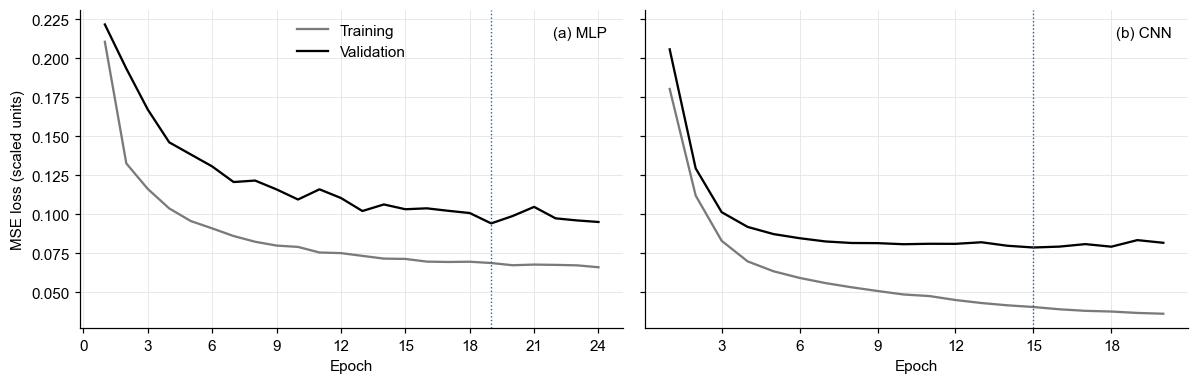

MLP: best epoch 19, training loss 0.0688, validation loss 0.0942
CNN: best epoch 15, training loss 0.0406, validation loss 0.0788


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (label, history) in zip(axes, [("(a) MLP", mlp_history), ("(b) CNN", cnn_history)]):
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    best = int(np.argmin(history.history["val_loss"])) + 1
    ax.plot(epochs, history.history["loss"], color=GREY, label="Training")
    ax.plot(epochs, history.history["val_loss"], color=BLACK, label="Validation")
    ax.axvline(best, color=ACCENT, linewidth=0.9, linestyle=":")
    ax.text(0.97, 0.95, label, transform=ax.transAxes, ha="right", va="top")
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("MSE loss (scaled units)")
axes[0].legend(loc="upper center")
plt.tight_layout()
plt.show()

for name, history in [("MLP", mlp_history), ("CNN", cnn_history)]:
    best = int(np.argmin(history.history["val_loss"]))
    print(f"{name}: best epoch {best + 1}, training loss {history.history['loss'][best]:.4f}, "
          f"validation loss {history.history['val_loss'][best]:.4f}")

**Fig. 4.** Training and validation loss per epoch for (a) the MLP and (b) the CNN; the dotted line marks the epoch with the lowest validation loss, whose weights are kept.

Both losses fall quickly over the first five epochs and then flatten. Validation loss stays above training loss, and the gap is wider for the CNN (0.041 training against 0.079 validation at its best epoch, 15) than for the MLP (0.069 against 0.094 at epoch 19), so both begin to overfit and early stopping keeps the weights from the best validation epoch. The CNN still reaches the lower validation loss with fewer parameters (91,256 against 110,744).

## 9. Validation Comparison and Model Selection

All models so far, compared on the validation set. The neural family with the lower validation RMSE goes to the grid search; the test set is still untouched.

**Table 5.** Validation comparison of baselines and starting neural models.

In [18]:
val_table = baseline_val.copy()
val_table["params"] = [0, 0, 0, ridge.coef_.size + ridge.intercept_.size]
val_table["train time (s)"] = [0.0, 0.0, 0.0, ridge_time]
for name, run in [("MLP", mlp_run), ("CNN", cnn_run)]:
    val_table.loc[name] = pd.Series({k: run[k] for k in val_table.columns})
val_table["params"] = val_table["params"].astype(int)
display(val_table.round(2))

best_family = "MLP" if mlp_run["RMSE (MW)"] <= cnn_run["RMSE (MW)"] else "CNN"  # a tie goes to the simpler MLP
print("Family selected for grid search:", best_family)

,MAE (MW),RMSE (MW),MAPE (%),params,train time (s)
Persistence,8856.56,11202.58,16.27,0,0.00
Seasonal naive 24 h,4628.96,7027.99,8.40,0,0.00
Seasonal naive 168 h,2411.02,4227.78,4.41,0,0.00
Linear AR (ridge),1524.32,2509.20,2.78,20184,1.09
MLP,2226.89,3089.38,4.03,110744,15.61
CNN,2019.22,2824.66,3.55,91256,34.88


Family selected for grid search: CNN


Both neural models beat every naive baseline on validation but not the linear AR model: the CNN reaches 2,825 MW RMSE and the MLP 3,089 MW, against 2,509 MW. The CNN has the lower validation RMSE, so the CNN grid is the one run in Section 10.

## 10. Grid Search

The search space, budget, objective and stopping rule are fixed here, before any grid result is shown. Each grid is 2 × 2, the same size as the Lab 4 (MLP) and Assignment 2 (CNN) grids.

| Item | MLP grid | CNN grid |
|---|---|---|
| Hyperparameters | hidden units {64, 128}; learning rate {0.01, 0.001} | filters {16, 32}; kernel size {3, 7}; learning rate fixed at 0.001 |
| Budget | 4 configurations | 4 configurations |
| Objective | Lowest validation RMSE (MW) | Lowest validation RMSE (MW) |
| Stopping rule per run | Early stopping on validation loss, patience 5, at most 30 epochs, best weights restored | Same |
| Tie-break | Fewer parameters | Fewer parameters |

Only the grid for the family selected in Section 9 is run. Each grid contains that family's starting configuration, and with the fixed seed that run is reproduced exactly, so the tuned model can only match or beat the starting model on validation.

**Table 6.** Grid search results, best first.

In [19]:
GRIDS = {
    "MLP": (build_mlp, {"units": [64, 128], "lr": [0.01, 0.001]}),
    "CNN": (build_cnn, {"filters": [16, 32], "kernel_size": [3, 7]}),
}
build_best, grid = GRIDS[best_family]

grid_runs = []
n_configs = int(np.prod([len(v) for v in grid.values()]))
grid_start = time.perf_counter()
for values in product(*grid.values()):
    config = dict(zip(grid, values))
    _, _, run = train_with_validation(build_best, config)
    grid_runs.append({**config, **run, "config": ", ".join(f"{k}={v}" for k, v in config.items())})
    print(f"{len(grid_runs)}/{n_configs} {config}: val RMSE {run['RMSE (MW)']:.0f} MW, "
          f"{run['epochs trained']} epochs, {run['train time (s)']:.0f} s", flush=True)
grid_time = time.perf_counter() - grid_start

grid_runs.sort(key=lambda r: (r["RMSE (MW)"], r["params"]))
grid_results = pd.DataFrame(grid_runs)
display(grid_results.drop(columns="config").round({"MAE (MW)": 1, "RMSE (MW)": 1, "MAPE (%)": 2, "train time (s)": 1}))

best_config = {k: grid_runs[0][k] for k in grid}
best_epochs = grid_runs[0]["best epoch"]
print(f"{best_family} grid: {len(grid_runs)} runs in {grid_time / 60:.1f} min")
print("Best configuration:", best_config, "| best epoch:", best_epochs)

1/4 {'filters': 16, 'kernel_size': 3}: val RMSE 2589 MW, 30 epochs, 43 s
2/4 {'filters': 16, 'kernel_size': 7}: val RMSE 2857 MW, 17 epochs, 29 s
3/4 {'filters': 32, 'kernel_size': 3}: val RMSE 2825 MW, 20 epochs, 37 s
4/4 {'filters': 32, 'kernel_size': 7}: val RMSE 2817 MW, 13 epochs, 32 s


,filters,kernel_size,MAE (MW),RMSE (MW),MAPE (%),params,best epoch,epochs trained,train time (s)
0,16,3,1826.5,2589.1,3.26,45672,29,30,42.6
1,32,7,2021.0,2816.7,3.59,95992,8,13,32.1
2,32,3,2019.2,2824.7,3.55,91256,15,20,37.4
3,16,7,2018.1,2857.4,3.59,47016,12,17,28.6


CNN grid: 4 runs in 2.4 min
Best configuration: {'filters': 16, 'kernel_size': 3} | best epoch: 29


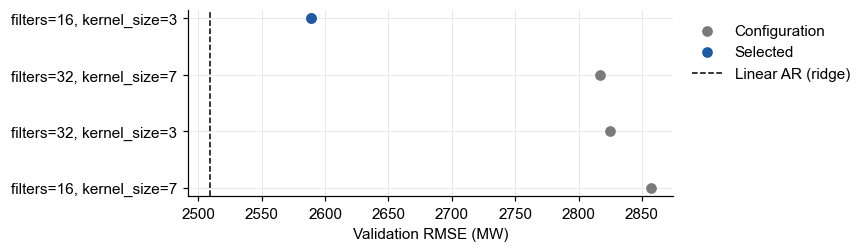

In [20]:
fig, ax = plt.subplots(figsize=(8, 0.3 * len(grid_results) + 1.2))
ax.scatter(grid_results["RMSE (MW)"], grid_results["config"], color=GREY, s=36, zorder=3, label="Configuration")
ax.scatter(grid_results["RMSE (MW)"][:1], grid_results["config"][:1], color=ACCENT, s=36, zorder=4, label="Selected")
ax.axvline(baseline_val.loc[best_baseline, "RMSE (MW)"], color=BLACK, linestyle="--", linewidth=1, label=best_baseline)
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_xlabel("Validation RMSE (MW)")
plt.tight_layout()
plt.show()

**Fig. 5.** Validation RMSE of every grid configuration, best first (highlighted). The dashed line is the best traditional baseline.

The selected configuration (16 filters, kernel size 3) reaches 2,589 MW, 8% below the starting CNN (2,825 MW) with half the parameters (45,672 against 91,256). The other three settings lie within 1.5% of each other (2,817–2,857 MW). The winner's best epoch is 29 of 30, so it was still improving when the 30-epoch cap stopped it; that cap is a limitation of the lab-sized budget. Even the tuned CNN stays 3% above the linear baseline on validation (2,589 against 2,509 MW).

## 11. Final Refit and Test Evaluation

With every choice locked, the Lab 3 (B7) and Assignment 2 (B5) protocol is applied to all trainable models alike: refit on train + validation with a scaler refitted on that development period, for the number of epochs at which each model's validation loss was lowest. Test windows are built inside the test split exactly as before. The test set is then used once, for every model and baseline in the same cell.

### 11.1 Refit on Train + Validation

In [21]:
dev = pd.concat([train, val])
final_scaler = StandardScaler()
dev_scaled = final_scaler.fit_transform(dev.to_numpy().reshape(-1, 1)).ravel()
test_scaled_final = final_scaler.transform(test.to_numpy().reshape(-1, 1)).ravel()

X_dev, y_dev = make_windows(feature_matrix(dev_scaled, dev.index), LOOKBACK, HORIZON)
X_test_final, y_test_final = make_windows(feature_matrix(test_scaled_final, test.index), LOOKBACK, HORIZON)
print("Development windows:", X_dev.shape, "| test windows:", X_test_final.shape)

def refit(build, config, epochs):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build(**config)
    start = time.perf_counter()
    model.fit(X_dev, y_dev, epochs=epochs, batch_size=BATCH_SIZE, shuffle=False, verbose=0)
    return model, time.perf_counter() - start

tuned_name = f"{best_family} (grid-tuned)"
final_specs = {
    "MLP": (build_mlp, MLP_START, mlp_run["best epoch"]),
    "CNN": (build_cnn, CNN_START, cnn_run["best epoch"]),
    tuned_name: (build_best, best_config, best_epochs),
}

final_models, train_time = {}, {name: 0.0 for name in NAIVE}
start = time.perf_counter()
final_ridge = Ridge(alpha=1.0).fit(flat(X_dev), y_dev)
train_time["Linear AR (ridge)"] = time.perf_counter() - start
for name, (build, config, epochs) in final_specs.items():
    final_models[name], train_time[name] = refit(build, config, epochs)
    print(f"{name}: {config}, {epochs} epochs, {train_time[name]:.1f} s")

Development windows: (40129, 168, 5) | test windows: (9889, 168, 5)
MLP: {'units': 128, 'lr': 0.001}, 19 epochs, 15.0 s
CNN: {'filters': 32, 'kernel_size': 3}, 15 epochs, 32.7 s
CNN (grid-tuned): {'filters': 16, 'kernel_size': 3}, 29 epochs, 45.3 s


### 11.2 Test Comparison

Inference time is measured on the full test set after a short warm-up call, so one-off graph tracing is not counted. Training time is the refit on train + validation; the grid search cost is reported separately.

**Table 7.** Test results and computational cost. Gains are relative to the best traditional baseline selected on validation.

In [22]:
def timed_predict(predict, X):
    predict(X[:256])
    start = time.perf_counter()
    pred = predict(X)
    return pred, (time.perf_counter() - start) / len(X) * 1e6  # ms per 1,000 windows

predictors = dict(NAIVE)
predictors["Linear AR (ridge)"] = lambda X: final_ridge.predict(flat(X))
for name, model in final_models.items():
    predictors[name] = lambda X, m=model: m.predict(X, batch_size=1024, verbose=0)

test_actual = to_mw(y_test_final, final_scaler)
test_preds, test_rows = {}, {}
for name, predict in predictors.items():
    pred_scaled, infer_ms = timed_predict(predict, X_test_final)
    test_preds[name] = to_mw(pred_scaled, final_scaler)
    test_rows[name] = {**score(test_actual, test_preds[name]), "inference (ms / 1k windows)": infer_ms}

params = {name: 0 for name in NAIVE}
params["Linear AR (ridge)"] = final_ridge.coef_.size + final_ridge.intercept_.size
params.update({name: m.count_params() for name, m in final_models.items()})

test_table = pd.DataFrame(test_rows).T
ref = test_table.loc[best_baseline]
test_table.insert(3, "RMSE gain (%)", 100 * (ref["RMSE (MW)"] - test_table["RMSE (MW)"]) / ref["RMSE (MW)"])
test_table.insert(4, "MAE gain (%)", 100 * (ref["MAE (MW)"] - test_table["MAE (MW)"]) / ref["MAE (MW)"])
test_table["params"] = pd.Series(params)
test_table["train time (s)"] = pd.Series(train_time)
display(test_table.round(2))

print(f"Reference baseline: {best_baseline} | grid search cost: {len(grid_runs)} runs, {grid_time / 60:.1f} min")

,MAE (MW),RMSE (MW),MAPE (%),RMSE gain (%),MAE gain (%),inference (ms / 1k windows),params,train time (s)
Persistence,8625.85,10905.40,16.65,-348.34,-462.73,0.05,0,0.00
Seasonal naive 24 h,4140.98,6323.61,7.83,-159.98,-170.15,0.00,0,0.00
Seasonal naive 168 h,2288.53,3919.30,4.38,-61.13,-49.30,0.00,0,0.00
Linear AR (ridge),1532.86,2432.38,2.94,0.00,0.00,0.55,20184,1.48
MLP,2115.59,2979.45,4.06,-22.49,-38.02,5.27,110744,15.01
CNN,2033.49,2813.44,3.84,-15.67,-32.66,10.17,91256,32.65
CNN (grid-tuned),1813.60,2542.96,3.50,-4.55,-18.31,8.61,45672,45.34


Reference baseline: Linear AR (ridge) | grid search cost: 4 runs, 2.4 min


The test results keep the validation ranking. The linear AR baseline is the most accurate model (2,432 MW RMSE, 2.94% MAPE). The grid-tuned CNN is second (2,543 MW, 3.50%), 4.5% worse in RMSE and 18% worse in MAE. Tuning improved the CNN by 9.6% in RMSE over the starting configuration (2,813 MW), and both CNNs beat the MLP (2,979 MW). Every trained model beats the seasonal naive baselines by a wide margin (168 h: 3,919 MW).

On cost, the linear model trains in seconds and predicts roughly ten to twenty times faster per window than the networks, which need between about 20 seconds and a minute to train on CPU, plus a few minutes for the grid search. At this stage the networks' extra parameters and training time do not buy accuracy over a linear autoregressive model.

### 11.3 Error by Forecast Step

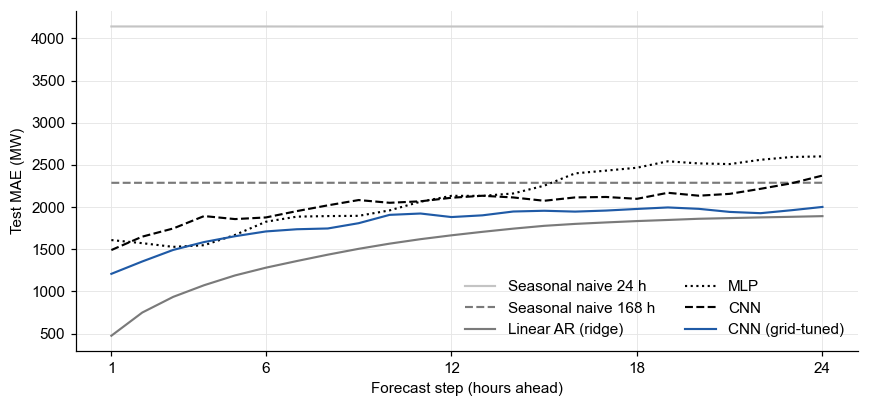

Persistence MAE at step 1 and 24 (MW): 1879 4140


In [23]:
step_mae = {name: np.abs(pred - test_actual).mean(axis=0) for name, pred in test_preds.items()}
styles = {
    "Seasonal naive 24 h": (LIGHT, "-"),
    "Seasonal naive 168 h": (GREY, "--"),
    "Linear AR (ridge)": (GREY, "-"),
    "MLP": (BLACK, ":"),
    "CNN": (BLACK, "--"),
    tuned_name: (ACCENT, "-"),
}
steps = np.arange(1, HORIZON + 1)

fig, ax = plt.subplots(figsize=(8, 3.8))
for name, (color, style) in styles.items():
    ax.plot(steps, step_mae[name], color=color, linestyle=style, linewidth=1.4, label=name)
ax.set_xticks([1, 6, 12, 18, 24])
ax.set_xlabel("Forecast step (hours ahead)")
ax.set_ylabel("Test MAE (MW)")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

print("Persistence MAE at step 1 and 24 (MW):", round(step_mae["Persistence"][0]), round(step_mae["Persistence"][-1]))

**Fig. 6.** Test MAE at each forecast step. Persistence is left out because its error grows far beyond the others (printed above).

Every model's error grows with the forecast step, but not equally. The linear model is far ahead for the first hours (under 500 MW MAE one hour ahead, against about 1,200 MW for the tuned CNN), because it uses the latest observed hours almost directly; the gap narrows to about 100–200 MW from step 12 onward. The networks therefore lose mainly in the first hours ahead. The MLP degrades fastest: beyond about 15 hours ahead its error exceeds even the 168 h seasonal naive.

### 11.4 Error Over Time and Failure Days

Each test day is scored once, using the day-ahead forecast issued at local midnight, so the daily error can be followed across the test period and the worst days can be listed.

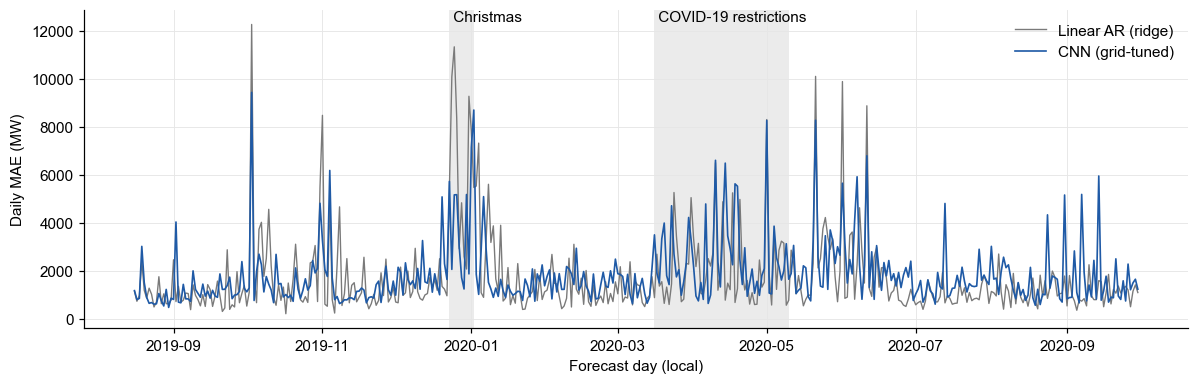

In [24]:
test_origins = test.index[LOOKBACK:len(test) - HORIZON + 1].tz_convert("Europe/Berlin")  # first forecast hour of each window
midnight = np.flatnonzero(test_origins.hour == 0)

days = test_origins[midnight].tz_localize(None).normalize()
daily_mae = pd.DataFrame({
    name: np.abs(test_preds[name][midnight] - test_actual[midnight]).mean(axis=1)
    for name in (best_baseline, tuned_name)
}, index=pd.Index(days, name="day"))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily_mae.index, daily_mae[best_baseline], color=GREY, linewidth=0.9, label=best_baseline)
ax.plot(daily_mae.index, daily_mae[tuned_name], color=ACCENT, linewidth=1.1, label=tuned_name)
ax.axvspan(pd.Timestamp("2019-12-23"), pd.Timestamp("2020-01-02"), color=GREY, alpha=0.15, linewidth=0)
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-05-10"), color=GREY, alpha=0.15, linewidth=0)
ax.text(pd.Timestamp("2019-12-23"), ax.get_ylim()[1], " Christmas", va="top")
ax.text(pd.Timestamp("2020-03-16"), ax.get_ylim()[1], " COVID-19 restrictions", va="top")
ax.set_xlabel("Forecast day (local)")
ax.set_ylabel("Daily MAE (MW)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Fig. 7.** Daily test MAE of the midnight day-ahead forecasts. Shaded: Christmas 2019 and the first COVID-19 restrictions in Germany (from 16 March 2020).

**Table 8.** The eight test days with the largest error for the tuned model.

In [25]:
worst = daily_mae.sort_values(tuned_name, ascending=False).head(8).round(0)
worst.insert(0, "weekday", worst.index.day_name())
display(worst)

,weekday,Linear AR (ridge),CNN (grid-tuned)
day,,,
2019-10-03,Thursday,12257.0,9426.0
2020-01-02,Thursday,5470.0,8694.0
2020-05-21,Thursday,10095.0,8268.0
2020-05-01,Friday,8297.0,8258.0
2020-01-01,Wednesday,7806.0,7140.0
2020-06-11,Thursday,8871.0,6787.0
2020-04-10,Friday,6502.0,6600.0
2020-04-14,Tuesday,778.0,6484.0


**Where the models fail.** Daily errors are usually 1–2 GW, with isolated spikes (Fig. 7). All eight of the tuned CNN's worst test days (Table 8) are public holidays or the working day right after one: German Unity Day (3 October 2019), New Year's Day and 2 January, Good Friday (10 April), the Tuesday after Easter Monday (14 April), Labour Day (1 May), Ascension Day (21 May) and Corpus Christi (11 June, a holiday in the southern and western states). On these days demand drops towards a Sunday level, but nothing in the inputs marks them, so the models forecast a normal working day. The linear model shares the weakness (its worst day is also 3 October, at 12.3 GW), although it handled 14 April far better than the CNN (0.8 against 6.5 GW). Errors are also higher and more erratic for both models during the COVID-19 restrictions, a regime absent from training.

## 12. Saved Model and Smoke Test

The locked model, its configuration and the development-period scaling are saved to `artifacts/` with the grid and test tables, so later stages and the TA can reuse them without retraining.

In [26]:
os.makedirs("artifacts", exist_ok=True)
final_models[tuned_name].save("artifacts/best_model.keras")
with open("artifacts/final_config.json", "w") as f:
    json.dump({
        "family": best_family, "config": best_config, "epochs": best_epochs,
        "lookback": LOOKBACK, "horizon": HORIZON, "features": FEATURES, "seed": SEED,
        "scaler_mean_MW": float(final_scaler.mean_[0]), "scaler_scale_MW": float(final_scaler.scale_[0]),
    }, f, indent=2)
grid_results.to_csv("artifacts/grid_results.csv", index=False)
test_table.to_csv("artifacts/test_comparison.csv")
print(sorted(os.listdir("artifacts")))

['best_model.keras', 'final_config.json', 'grid_results.csv', 'test_comparison.csv']


Smoke test: reload the saved model and reproduce the first test forecasts without any training. This cell runs in a few seconds.

In [27]:
loaded = tf.keras.models.load_model("artifacts/best_model.keras")
smoke = to_mw(loaded.predict(X_test_final[:5], verbose=0), final_scaler)

assert smoke.shape == (5, HORIZON)
assert np.allclose(smoke, test_preds[tuned_name][:5], atol=1e-2)
print("Smoke test passed. First forecast (GW):", np.round(smoke[0] / 1000, 1))

Smoke test passed. First forecast (GW): [40.  39.9 40.7 42.7 46.6 52.  56.3 58.5 59.2 59.3 59.1 58.3 57.  55.9
 55.8 56.1 55.9 54.8 53.3 51.4 48.9 45.7 43.  41.5]


## 13. Conclusion and Next Steps

**Conclusion.** For day-ahead forecasting of German hourly load, a linear autoregressive model on the past week is the best Stage 1 model, on validation (2,509 MW RMSE) and on test (2,432 MW RMSE, 2.94% MAPE). The grid-tuned CNN is the best neural model (2,543 MW test RMSE): it beats both seasonal naive baselines by a wide margin and improves on the starting CNN by 9.6%, but it does not beat the linear baseline, and it costs more to train and run. Its disadvantage is concentrated in the first hours ahead (Fig. 6).

**Unresolved risk.** Public holidays. All eight of the tuned CNN's worst test days are public holidays or the day after one (Table 8), and no input marks them, so every model forecasts a normal working day. A public-holiday flag is a future-known calendar input that the protocol allows; whether it helps has to be decided on validation data, not on these test days.

**Next steps for Stage 2.** Keep the same split, windows and metrics for the RNN, LSTM/GRU and TCN models. Check on validation whether the networks are held back by the training setup: the lab protocol feeds mini-batches in chronological order (`shuffle=False`), and the selected CNN was still improving at the 30-epoch cap.

## References

1. Open Power System Data. 2020. Data Package Time series. Version 2020-10-06. https://doi.org/10.25832/time_series/2020-10-06 (primary data: ENTSO-E Transparency Platform). Processing documentation: https://github.com/Open-Power-System-Data/datapackage_timeseries/blob/2020-10-06/processing.ipynb
2. TensorFlow and Keras, https://www.tensorflow.org; scikit-learn, https://scikit-learn.org; pandas, NumPy and Matplotlib.
3. AISE 4010 Lectures 2–4, Lab 3 (MLP) and Assignment 2 (CNN) notebooks, for the split, windowing, baseline, grid search and refit protocol.